# 04 — Analisis Bivariat dan Multivariat
### Milestone M3 (dinilai saat UTS) · Pertemuan 7 · Exploratory Data Analysis (KMTI21133)

| | |
|---|---|
| **Nama tim** | Kelompok-EDA_AI01 |
| **Anggota** | Abdul Aziz Al Palembani, Fahri Mulyadi, Lukman Maruf, Nicha Amelia SRG |
| **Topik proyek** | Beban COVID-19 antarprovinsi di Indonesia, 1 Januari – 15 September 2022 |
| **Tanggal** | [TANGGAL] |

**Notebook ini mengisi:** dimensi **Analisis bivariat dan multivariat** (25), **Ketepatan teknik dan asumsi** (15), **Kualitas visualisasi** (15), dan **Interpretasi dan keterkaitan dengan pertanyaan** (25) pada Rubrik M3.

Menjawab **Pertanyaan 2** (apakah provinsi yang lebih padat juga lebih banyak terkena?) dan **Pertanyaan 4** (kematian per 1.000 kasus, dan perbedaannya antarpulau), serta menghasilkan **korelasi acuan Python** untuk bagian korelasi workflow KNIME (M4).

**Aturan bahasa:** tidak ada kalimat sebab-akibat. Kami memakai "berkaitan dengan" dan "cenderung disertai".

**Isi minimal M3 yang dipenuhi:** (1) heatmap Pearson dan Spearman berdampingan; (2) dua scatter plot dengan tafsiran; (3) tabel silang ternormalisasi per baris + Cramér's V; (4) faceting; (5) paragraf variabel perancu.

**Kesinambungan.** Tabel provinsi dibaca dari keluaran M1 (`covid_2022_provinsi.csv`) lalu **diuji ulang terhadap data olahan 02** dengan `assert`; hasil kelompok kepadatan M1 dipertemukan dengan analisis korelasi di bagian 2c. Notebook ini melanjutkan variabel yang disiapkan di `03_univariate.ipynb`.

---
> **Sebelum mengumpulkan:** jalankan **Kernel → Restart & Run All**.

In [1]:
# Notebook ini berada di notebooks/. Semua path di bawah relatif terhadap AKAR repositori,
# jadi pindah ke akar bila dijalankan dari folder notebooks/ (aman dijalankan dari mana pun).
import os
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
DATA, SOROT, REDUP = '#0E7490', '#C2410C', '#5B6672'

PROCESSED, FIGURES, REPORTS = 'data/processed', 'reports/figures', 'reports'
os.makedirs(FIGURES, exist_ok=True)
W0, W1 = pd.Timestamp('2022-01-01'), pd.Timestamp('2022-09-15')
rb = lambda v: f'{v:,.0f}'.replace(',', '.')
ribuan = FuncFormatter(lambda v, _: rb(v))

## 0. Satuan amatan, dan uji kesinambungan dengan M1 dan 02

Satu baris = **satu provinsi** (n = 34). Semua korelasi memakai **n = 34 provinsi** (tidak ada nilai kosong, sehingga n setelah `dropna()` tetap 34). Ukuran sampel kecil dan 7 kelompok pulau membuat hasil bersifat **eksploratif**: pola yang terlihat bukan bukti. Setiap korelasi disertai scatter plot-nya.

"Padat" dioperasionalkan sebagai **kepadatan penduduk (jiwa/km²)**, bukan jumlah penduduk. Jumlah penduduk ikut diperiksa sebagai pembanding karena provinsi berpenduduk besar secara aritmetika memiliki lebih banyak kasus.

In [2]:
p = pd.read_csv(f'{PROCESSED}/covid_2022_provinsi.csv')              # keluaran M1 (n = 34)

# Uji ulang terhadap data olahan 02: kasus dan kematian harus sama dengan jumlah new_cases/new_deaths di jendela
d = pd.read_csv(f'{PROCESSED}/covid_provinsi_bersih.csv', parse_dates=['date'])
w = d[d['date'].between(W0, W1)]
agg = w.groupby('location').agg(kasus=('new_cases', 'sum'), kematian=('new_deaths', 'sum'), luas_km2=('area_km2', 'first')).reset_index().rename(columns={'location': 'provinsi'})
c = p.merge(agg, on='provinsi', suffixes=('', '_02'), validate='1:1')
assert len(c) == 34 and (c['kasus'] == c['kasus_02']).all() and (c['kematian'] == c['kematian_02']).all()
assert p['kasus'].sum() == 2_134_660 and p['kematian'].sum() == 13_683
p = p.merge(agg[['provinsi', 'luas_km2']], on='provinsi')            # luas wilayah (km2), tidak ada di keluaran M1
print('LOLOS: tabel M1 sama dengan data olahan 02 (kasus, kematian). n =', len(p), 'provinsi.')
p.head(3).round(1)

LOLOS: tabel M1 sama dengan data olahan 02 (kasus, kematian). n = 34 provinsi.


,provinsi,pulau,penduduk,kepadatan,hari_data,kasus,kematian,kasus_per_juta,kematian_per_juta,kelompok_kepadatan,kematian_per_1000_kasus,luas_km2
0,Aceh,Sumatera,5247257,90.5,258,5608,157,1068.8,29.9,Sedang,28.0,57956
1,Bali,Nusa Tenggara,4216171,729.4,258,52442,670,12438.3,158.9,Padat,12.8,5780
2,Banten,Jawa,10722374,1109.6,258,201049,256,18750.4,23.9,Padat,1.3,9663


## 1. Heatmap korelasi: Pearson dan Spearman berdampingan

**Mengapa dua ukuran dan mengapa Spearman menjadi acuan.** Pearson mengukur hubungan *linear* dan peka terhadap nilai ekstrem; di `03_univariate.ipynb` terbukti kepadatan, kasus, dan penduduk **sangat menjulur** dengan satu provinsi ekstrem (DKI Jakarta). Spearman bekerja pada peringkat dan tahan terhadap nilai ekstrem. **Pilihan didasarkan pada sifat data, bukan pada angka mana yang lebih besar.** Heatmap hanya dipakai untuk *memilih pasangan*, bukan untuk menyimpulkan.

Kedua panel memakai skala warna yang sama (`vmin=-1, vmax=1`, pusat 0).

n setelah dropna(): 34


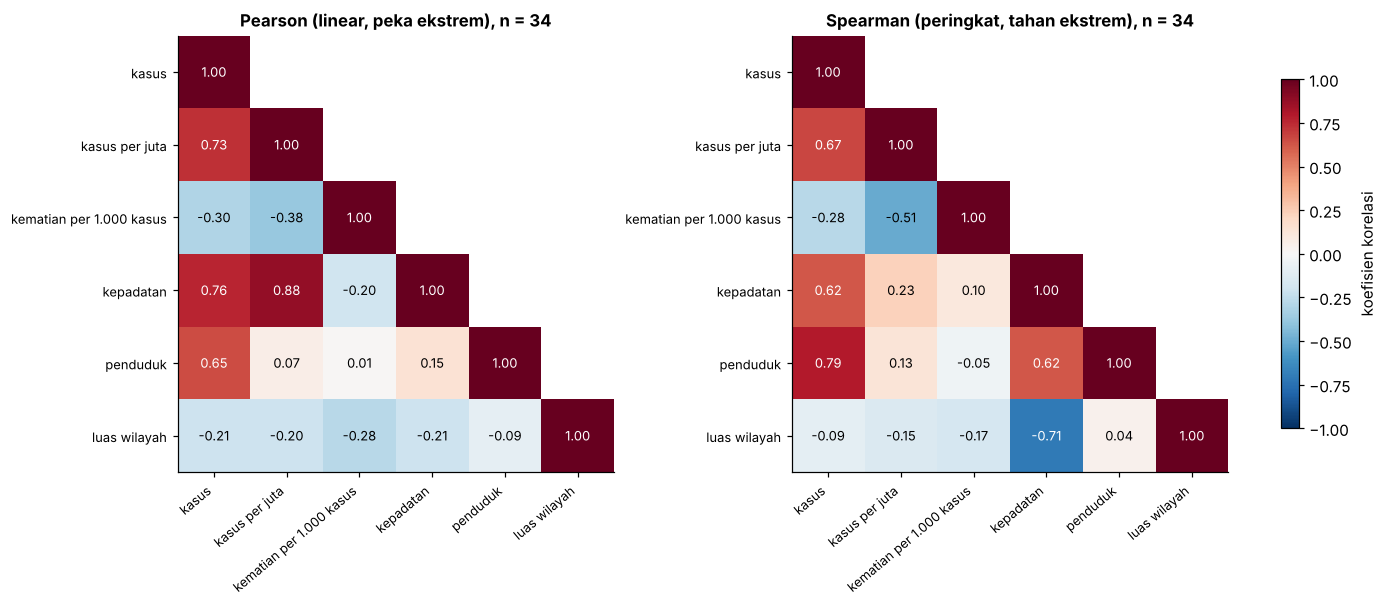

Pasangan dengan selisih Pearson-Spearman terbesar (petunjuk nilai ekstrem/non-linear):
variabel_1              variabel_2  n  pearson_r  pearson_p  spearman_rho  spearman_p  selisih
 kepadatan          kasus_per_juta 34       0.88       0.00          0.23        0.20     0.65
  luas_km2               kepadatan 34      -0.21       0.24         -0.71        0.00     0.50
  penduduk               kepadatan 34       0.15       0.41          0.62        0.00     0.48
 kepadatan kematian_per_1000_kasus 34      -0.20       0.26          0.10        0.56     0.30
 kepadatan                   kasus 34       0.76       0.00          0.62        0.00     0.15
  penduduk                   kasus 34       0.65       0.00          0.79        0.00     0.14


In [3]:
VAR = {'kasus': 'kasus', 'kasus_per_juta': 'kasus per juta', 'kematian_per_1000_kasus': 'kematian per 1.000 kasus',
       'kepadatan': 'kepadatan', 'penduduk': 'penduduk', 'luas_km2': 'luas wilayah'}
X = p[list(VAR)].dropna()
n_dropna = len(X); assert n_dropna == 34
print('n setelah dropna():', n_dropna)

pear = X.corr('pearson').rename(index=VAR, columns=VAR)
spea = X.corr('spearman').rename(index=VAR, columns=VAR)

def heat(ax, M, judul):
    mask = np.triu(np.ones_like(M, dtype=bool), k=1)
    im = ax.imshow(np.ma.array(M.values, mask=mask), cmap='RdBu_r', vmin=-1, vmax=1)
    for i in range(len(M)):
        for j in range(len(M)):
            if not mask[i, j]:
                ax.text(j, i, f'{M.values[i, j]:.2f}', ha='center', va='center', fontsize=8.5,
                        color='white' if abs(M.values[i, j]) > .6 else 'black')
    ax.set_xticks(range(len(M))); ax.set_yticks(range(len(M)))
    ax.set_xticklabels(M.columns, rotation=40, ha='right', fontsize=8.5); ax.set_yticklabels(M.index, fontsize=8.5)
    ax.grid(False); ax.set_title(judul)
    return im
fig, ax = plt.subplots(1, 2, figsize=(12.5, 5.4), layout='constrained')
heat(ax[0], pear, f'Pearson (linear, peka ekstrem), n = {n_dropna}')
im = heat(ax[1], spea, f'Spearman (peringkat, tahan ekstrem), n = {n_dropna}')
fig.colorbar(im, ax=ax, shrink=.8, label='koefisien korelasi')
plt.savefig(f'{FIGURES}/p7_heatmap.png', dpi=150); plt.show()

pasang = []
for i, a in enumerate(X.columns):
    for b in X.columns[:i]:
        pr, pp = stats.pearsonr(X[a], X[b]); sr, sp = stats.spearmanr(X[a], X[b])
        pasang.append({'variabel_1': a, 'variabel_2': b, 'n': n_dropna, 'pearson_r': pr, 'pearson_p': pp, 'spearman_rho': sr, 'spearman_p': sp})
tbl = pd.DataFrame(pasang).assign(selisih=lambda t: (t.pearson_r - t.spearman_rho).abs()).sort_values('selisih', ascending=False)
print('Pasangan dengan selisih Pearson-Spearman terbesar (petunjuk nilai ekstrem/non-linear):')
print(tbl.head(6).round(2).to_string(index=False))

**Membaca heatmap — memilih pasangan, bukan menyimpulkan.**
1. **kepadatan × kasus per juta**: Pearson 0,88 tetapi Spearman hanya 0,23, selisih terbesar pada seluruh matriks. Selisih sebesar ini khas satu atau beberapa nilai ekstrem yang menarik korelasi linear.
2. **kepadatan × kasus**: Pearson 0,76 dan Spearman 0,62; kedua ukuran sepakat ada hubungan positif, hanya besarnya berbeda.
3. Untuk Pertanyaan 4: **kasus per juta × kematian per 1.000 kasus** negatif pada kedua ukuran (Pearson −0,38; Spearman −0,51).

Karena data menjulur kuat dengan pengaruh Jakarta, **Spearman dijadikan ukuran utama**; Pearson dilaporkan sebagai pembanding untuk menunjukkan seberapa besar pengaruh nilai ekstrem.

## 2. Dua scatter plot untuk pasangan paling menarik — Pertanyaan 2

Setiap angka korelasi disertai scatter plot-nya. Sumbu memakai skala logaritmik karena kepadatan menjulur kuat; **koefisien dihitung pada nilai asli** (Spearman tidak berubah oleh transformasi monoton). Provinsi paling ekstrem diberi label.

In [4]:
def scatter(ax, x, y, xlab, ylab, judul, label_n=4):
    t = p[['provinsi', x, y]].dropna()
    ax.scatter(t[x], t[y], s=42, color=DATA, alpha=.85, edgecolor='white', linewidth=.6)
    ext = pd.concat([t.nlargest(label_n, y), t.nlargest(label_n, x)]).drop_duplicates('provinsi')
    for _, r in ext.iterrows():
        ax.annotate(r['provinsi'].replace('Daerah Istimewa ', 'DI '), (r[x], r[y]), xytext=(5, 4), textcoords='offset points', fontsize=7.5, color=REDUP)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel(xlab); ax.set_ylabel(ylab); ax.set_title(judul)

def lapor(x, y, tanpa=None):
    t = p[['provinsi', x, y]].dropna()
    pr, pp = stats.pearsonr(t[x], t[y]); sr, sp = stats.spearmanr(t[x], t[y])
    print(f'n = {len(t)}   Pearson r = {pr:+.2f} (p = {pp:.3g})   Spearman rho = {sr:+.2f} (p = {sp:.3g})')
    if tanpa:
        e = t[t['provinsi'] != tanpa]
        pr2, _ = stats.pearsonr(e[x], e[y]); sr2, sp2 = stats.spearmanr(e[x], e[y])
        print(f'tanpa {tanpa} (n = {len(e)}):  Pearson r = {pr2:+.2f}   Spearman rho = {sr2:+.2f} (p = {sp2:.3g})')

### 2a. Kepadatan × kasus per juta penduduk

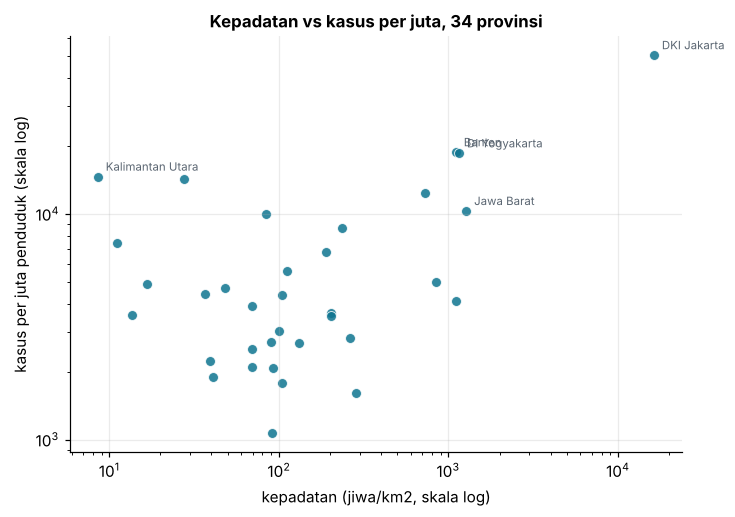

n = 34   Pearson r = +0.88 (p = 1.07e-11)   Spearman rho = +0.23 (p = 0.198)
tanpa DKI Jakarta (n = 33):  Pearson r = +0.52   Spearman rho = +0.15 (p = 0.392)


In [5]:
fig, ax = plt.subplots(figsize=(6.8, 4.8))
scatter(ax, 'kepadatan', 'kasus_per_juta', 'kepadatan (jiwa/km2, skala log)', 'kasus per juta penduduk (skala log)', 'Kepadatan vs kasus per juta, 34 provinsi')
plt.tight_layout(); plt.savefig(f'{FIGURES}/p7_scatter_kepadatan_kasuspj.png', dpi=150); plt.show()
lapor('kepadatan', 'kasus_per_juta', tanpa='DKI Jakarta')

**Tafsiran 2a.** Pada seluruh 34 provinsi, Pearson 0,88 (tampak sangat kuat) sedangkan Spearman hanya 0,23 (p ≈ 0,20, tidak dapat dibedakan dari nol dengan n sekecil ini). Scatter plot menjelaskan selisihnya: **DKI Jakarta berada jauh di pojok kanan atas** (16.334 jiwa/km², 50.452 kasus per juta), sedangkan 33 provinsi lainnya tidak membentuk pola jelas. Tanpa Jakarta, Pearson turun menjadi 0,52 dan Spearman 0,15 (tidak bermakna). **Hubungan "provinsi lebih padat cenderung berkasus per kapita lebih tinggi" hampir sepenuhnya ditopang satu titik.** Spearman dipilih karena data menjulur dan ada *leverage*; Pearson 0,88 tidak boleh dilaporkan sebagai temuan tunggal.

### 2b. Kepadatan × jumlah kasus

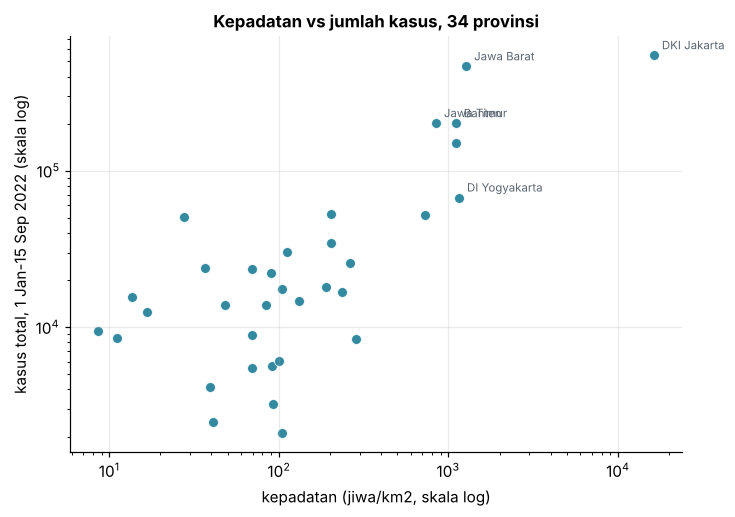

n = 34   Pearson r = +0.76 (p = 1.41e-07)   Spearman rho = +0.62 (p = 9.83e-05)
tanpa DKI Jakarta (n = 33):  Pearson r = +0.80   Spearman rho = +0.58 (p = 0.000379)
Pembanding: penduduk x kasus -> n = 34   Pearson r = +0.65 (p = 2.69e-05)   Spearman rho = +0.79 (p = 2.75e-08)
Kepadatan x penduduk       -> n = 34   Pearson r = +0.15 (p = 0.411)   Spearman rho = +0.62 (p = 7.83e-05)


In [6]:
fig, ax = plt.subplots(figsize=(6.8, 4.8))
scatter(ax, 'kepadatan', 'kasus', 'kepadatan (jiwa/km2, skala log)', 'kasus total, 1 Jan-15 Sep 2022 (skala log)', 'Kepadatan vs jumlah kasus, 34 provinsi')
plt.tight_layout(); plt.savefig(f'{FIGURES}/p7_scatter_kepadatan_kasus.png', dpi=150); plt.show()
lapor('kepadatan', 'kasus', tanpa='DKI Jakarta')
print('Pembanding: penduduk x kasus ->', end=' '); lapor('penduduk', 'kasus')
print('Kepadatan x penduduk       ->', end=' '); lapor('kepadatan', 'penduduk')

**Tafsiran 2b.** Hubungan positif bertahan: Spearman 0,62 (p < 0,001) dan tetap 0,58 tanpa Jakarta; Pearson 0,76 (0,80 tanpa Jakarta). Berbeda dari 2a, di sini hubungannya **tidak ditopang satu titik**. Namun **jumlah penduduk berkaitan lebih kuat dengan jumlah kasus** (Spearman 0,79) daripada kepadatan; jumlah kasus mentah sebagian besar mencerminkan besarnya populasi. Kepadatan dan penduduk sendiri saling berkaitan (Spearman 0,62), sehingga keduanya tidak dapat dipisahkan dengan data ini. Jawaban sementara Pertanyaan 2: **provinsi yang lebih padat cenderung disertai jumlah kasus lebih banyak, tetapi tidak cenderung disertai kasus per kapita yang jelas lebih tinggi kecuali karena Jakarta.**

### 2c. Mempertemukan dengan hasil M1: tiga kelompok kepadatan

M1 menjawab Pertanyaan 2 dengan tiga kelompok kepadatan (persentil) dan membandingkan **nilai tengah** kasus per juta, ukuran yang tahan terhadap ekstrem. Di sini hasil itu diuji ulang dan disandingkan dengan korelasi.

In [7]:
g = (p.groupby('kelompok_kepadatan', observed=True)
      .agg(jumlah_provinsi=('provinsi', 'count'), kepadatan_min=('kepadatan', 'min'), kepadatan_maks=('kepadatan', 'max'),
           median_kasus_per_juta=('kasus_per_juta', 'median'), kasus=('kasus', 'sum'))
      .reindex(['Jarang', 'Sedang', 'Padat']))
m1q2 = pd.read_csv('reports/tabel_m1/q2_kelompok_kepadatan.csv').set_index('kelompok_kepadatan').reindex(g.index)
assert np.allclose(g['median_kasus_per_juta'], m1q2['nilai_tengah_kasus_per_juta'], atol=0.06) and (g['jumlah_provinsi'] == m1q2['jumlah_provinsi']).all()
print('LOLOS: sama dengan tabel M1 (reports/tabel_m1/q2_kelompok_kepadatan.csv)\n')
print(g.round(1).to_string())

padat_tanpa = p[(p.kelompok_kepadatan == 'Padat') & (p.provinsi != 'DKI Jakarta')]['kasus_per_juta']
print(f'\nMedian kelompok Padat TANPA DKI Jakarta (n = {len(padat_tanpa)}): {padat_tanpa.median():,.1f}')
H, pH = stats.kruskal(*[x['kasus_per_juta'].values for _, x in p.groupby('kelompok_kepadatan', observed=True)])
print(f'Kruskal-Wallis kasus per juta antar 3 kelompok: H = {H:.2f}, p = {pH:.3f}')

LOLOS: sama dengan tabel M1 (reports/tabel_m1/q2_kelompok_kepadatan.csv)

                    jumlah_provinsi  kepadatan_min  kepadatan_maks  median_kasus_per_juta    kasus
kelompok_kepadatan                                                                                
Jarang                           12            8.6            69.8                 4158.8   179277
Sedang                           11           84.0           201.8                 3034.7   167924
Padat                            11          203.8         16334.3                 8640.5  1787459

Median kelompok Padat TANPA DKI Jakarta (n = 10): 6,809.0
Kruskal-Wallis kasus per juta antar 3 kelompok: H = 4.69, p = 0.096


**Tafsiran 2c.** Tabel ini sama dengan M1: median kasus per juta **Padat 8.641**, **Jarang 4.159**, **Sedang 3.035**. Urutannya **tidak monoton**: kelompok Jarang berada di atas Sedang, sehingga "makin padat makin tinggi" tidak berlaku mulus pada seluruh rentang. Tanpa Jakarta, median kelompok Padat turun menjadi 6.809 (n = 10) tetapi tetap tertinggi, jadi kelompok Padat tidak sepenuhnya bergantung pada Jakarta. Perbedaan antar tiga kelompok tidak bermakna pada n = 34 (Kruskal-Wallis p ≈ 0,096). Hasil ini **sejalan** dengan korelasi peringkat yang lemah (Spearman 0,23): ada kecenderungan kelompok Padat lebih tinggi, tetapi tidak cukup kuat untuk disebut pola pasti. Kedua pendekatan, korelasi dan kelompok persentil, memberi jawaban yang sama; angka M1 tidak berubah.

## 3. Faceting: apakah pola kepadatan–kasus per juta berubah menurut pulau?

Scatter 2a dipecah menurut `pulau`. Semua panel memakai **sumbu x dan y yang sama**. Spearman per panel hanya dihitung bila n ≥ 5; dengan n lebih kecil koefisien tidak bermakna.

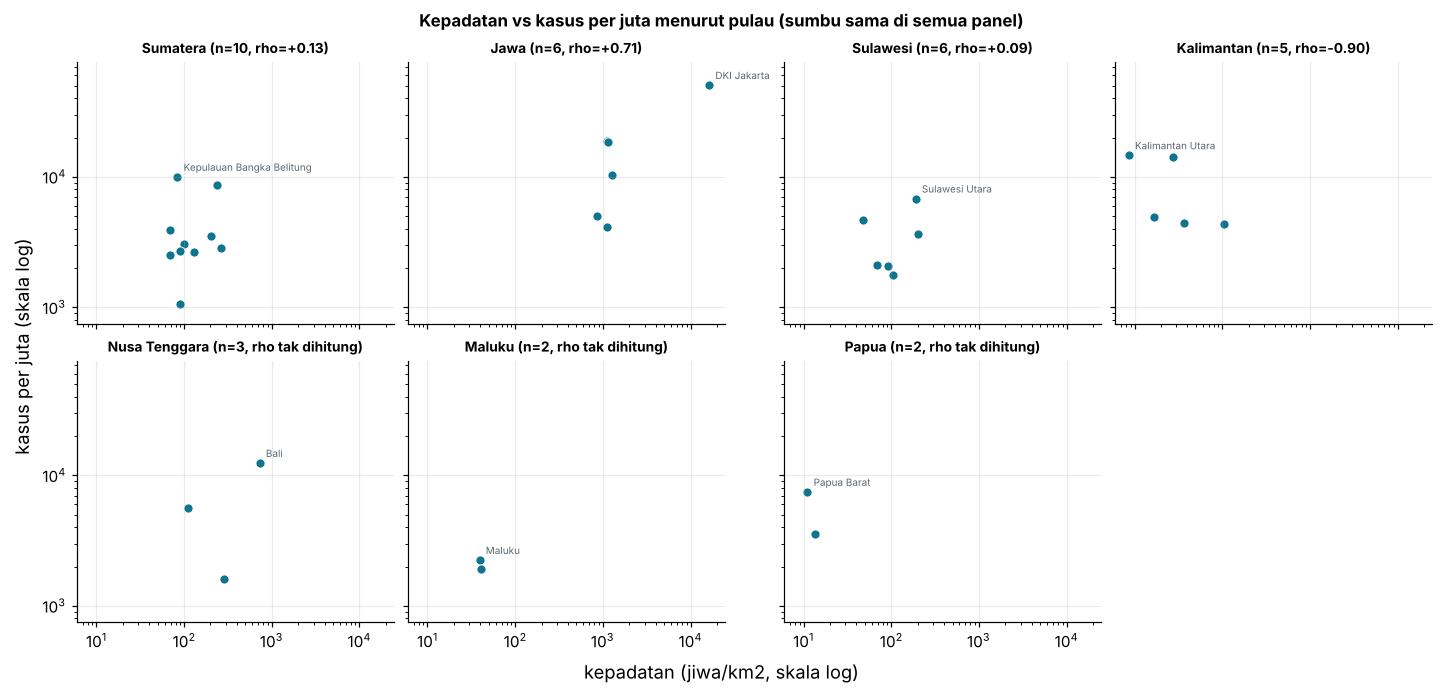

{'Sumatera': np.float64(0.13), 'Jawa': np.float64(0.71), 'Sulawesi': np.float64(0.09), 'Kalimantan': np.float64(-0.9)}


In [8]:
urut = p['pulau'].value_counts().index.tolist()
xl = (p['kepadatan'].min() * .7, p['kepadatan'].max() * 1.5); yl = (p['kasus_per_juta'].min() * .7, p['kasus_per_juta'].max() * 1.5)
fig, axs = plt.subplots(2, 4, figsize=(13, 6.2), sharex=True, sharey=True, layout='constrained')
rho_pulau = {}
for a, nama in zip(axs.flat, urut):
    t = p[p['pulau'] == nama]
    a.scatter(t['kepadatan'], t['kasus_per_juta'], s=36, color=DATA, edgecolor='white', linewidth=.6)
    a.set_xscale('log'); a.set_yscale('log'); a.set_xlim(xl); a.set_ylim(yl)
    if len(t) >= 5:
        rho = stats.spearmanr(t['kepadatan'], t['kasus_per_juta'])[0]; rho_pulau[nama] = rho
        a.set_title(f'{nama} (n={len(t)}, rho={rho:+.2f})', fontsize=9)
    else:
        a.set_title(f'{nama} (n={len(t)}, rho tak dihitung)', fontsize=9)
    r = t.nlargest(1, 'kasus_per_juta').iloc[0]
    a.annotate(r['provinsi'].replace('Daerah Istimewa ', 'DI '), (r['kepadatan'], r['kasus_per_juta']), xytext=(4, 4), textcoords='offset points', fontsize=6.5, color=REDUP)
for a in axs.flat[len(urut):]: a.set_visible(False)
fig.supxlabel('kepadatan (jiwa/km2, skala log)'); fig.supylabel('kasus per juta (skala log)')
fig.suptitle('Kepadatan vs kasus per juta menurut pulau (sumbu sama di semua panel)', fontsize=11, fontweight='bold')
plt.savefig(f'{FIGURES}/p7_facet_pulau.png', dpi=150); plt.show()
print({k: round(v, 2) for k, v in rho_pulau.items()})

**Keterangan faceting.** **Polanya berubah menurut pulau, dan arahnya tidak konsisten**: di Jawa korelasi peringkat positif kuat (ρ = +0,71, n = 6; sebagian karena Jakarta), di Sulawesi dan Sumatera hampir nol (+0,09 dan +0,13), di Kalimantan negatif kuat (−0,90, n = 5). Koefisien ini **tidak dapat ditafsirkan sebagai perbedaan nyata**: n per panel hanya 5–10, satu titik dapat membalik tandanya, dan Maluku, Nusa Tenggara, serta Papua (n = 2–3) terlalu kecil. Kesimpulan aman: **tidak ada hubungan kepadatan–kasus per kapita yang seragam di seluruh pulau**; korelasi antar-34 provinsi (2a) adalah campuran perbedaan *antar*pulau (Jawa padat dan berkasus per kapita tinggi) dan hubungan *di dalam* pulau. Perbedaan tingkat pulau inilah kandidat perancu (bagian 6).

## 4. Pertanyaan 4 — kematian per 1.000 kasus menurut pulau

Dari tiap 1.000 orang yang tercatat terkena, berapa yang meninggal, dan apakah berbeda antarpulau? Ukuran dihitung dari **jumlah agregat** (kematian ÷ kasus × 1.000), per pulau dan per provinsi.

               jumlah_provinsi    kasus  kematian  gabungan  median_provinsi
pulau                                                                       
Sumatera                    10   190154      2163      11.4             12.1
Nusa Tenggara                3    91044       934      10.3             10.0
Maluku                       2     6630        61       9.2              9.8
Sulawesi                     6    77166       636       8.2              8.8
Kalimantan                   5   114175       716       6.3              5.4
Jawa                         6  1631428      9125       5.6              6.6
Papua                        2    24063        48       2.0              2.3

Nasional (34 provinsi, gabungan): 6.41 kematian per 1.000 kasus


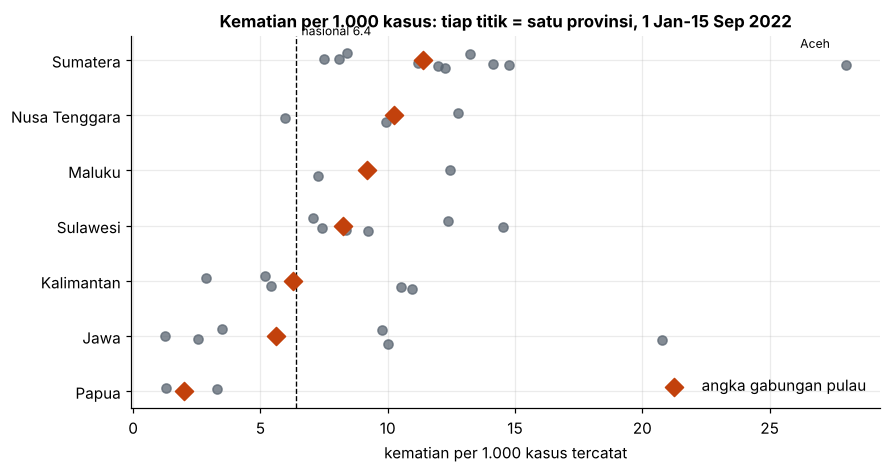

Kruskal-Wallis antar 7 pulau (unit = provinsi): H = 10.64, p = 0.100


In [9]:
pulau = (p.groupby('pulau').agg(jumlah_provinsi=('provinsi', 'count'), kasus=('kasus', 'sum'), kematian=('kematian', 'sum'))
          .assign(gabungan=lambda x: x.kematian / x.kasus * 1000,
                  median_provinsi=p.groupby('pulau')['kematian_per_1000_kasus'].median())
          .sort_values('gabungan', ascending=False))
nas = p['kematian'].sum() / p['kasus'].sum() * 1000
print(pulau.round(1).to_string()); print(f'\nNasional (34 provinsi, gabungan): {nas:.2f} kematian per 1.000 kasus')

urut = pulau.index.tolist(); rng = np.random.default_rng(42)
fig, ax = plt.subplots(figsize=(8.2, 4.4))
for i, k in enumerate(urut):
    v = p.loc[p['pulau'] == k, 'kematian_per_1000_kasus']
    ax.scatter(v, i + rng.uniform(-.15, .15, len(v)), s=36, color=REDUP, alpha=.75, zorder=3)
ax.scatter(pulau['gabungan'], range(len(urut)), marker='D', s=70, color=SOROT, zorder=5, label='angka gabungan pulau')
ax.axvline(nas, color='black', lw=.9, ls='--'); ax.text(nas + .2, -0.45, f'nasional {nas:.1f}', fontsize=8)
a = p.loc[p.provinsi == 'Aceh'].iloc[0]; ax.annotate('Aceh', (a.kematian_per_1000_kasus, urut.index('Sumatera')), xytext=(-30, 8), textcoords='offset points', fontsize=8)
ax.set_yticks(range(len(urut))); ax.set_yticklabels(urut); ax.invert_yaxis()
ax.set_xlabel('kematian per 1.000 kasus tercatat'); ax.legend(frameon=False, loc='lower right')
ax.set_title('Kematian per 1.000 kasus: tiap titik = satu provinsi, 1 Jan-15 Sep 2022')
plt.tight_layout(); plt.savefig(f'{FIGURES}/p7_kematian_pulau.png', dpi=150); plt.show()

kel = [t['kematian_per_1000_kasus'].values for _, t in p.groupby('pulau')]
H4, pH4 = stats.kruskal(*kel)
print(f'Kruskal-Wallis antar 7 pulau (unit = provinsi): H = {H4:.2f}, p = {pH4:.3f}')

**Tafsiran.** **Angka gabungan** berbeda cukup jauh: Sumatera 11,4, Nusa Tenggara 10,3, dan Maluku 9,2 per 1.000 kasus di atas nasional (6,4), sedangkan Jawa 5,6 dan Papua 2,0 di bawahnya (cocok dengan tabel pulau M1). Namun ada **dua catatan penting**: (1) angka gabungan Jawa rendah terutama karena provinsi berkasus sangat banyak (Jakarta 3,5; Jawa Barat 2,5; Banten 1,3), padahal Jawa Tengah (20,8) adalah yang kedua tertinggi di Indonesia, sehingga rentang di dalam pulau lebih besar daripada selisih antarpulau; (2) tingginya Sumatera sebagian ditarik Aceh (28,0). Uji Kruskal-Wallis pada tingkat provinsi **tidak menemukan perbedaan yang jelas antarpulau (p ≈ 0,10; n = 34, 7 kelompok)**. Jawaban sementara: **angka gabungan antarpulau tampak berbeda, tetapi dengan data ini perbedaan itu tidak dapat dipisahkan dari variasi antarprovinsi di dalam satu pulau.**

## 5. Tabel silang ternormalisasi per baris dan Cramér's V

Pulau × kelompok tingkat kematian (rendah / sedang / tinggi menurut tertil `kematian_per_1000_kasus`). Setiap baris dijumlahkan menjadi 100%, sehingga terbaca "dari provinsi di pulau X, berapa persen yang masuk kelompok tinggi".

Batas tertil: {'rendah': {'min': 1.3, 'max': 7.4}, 'sedang': {'min': 7.5, 'max': 11.2}, 'tinggi': {'min': 12.0, 'max': 28.0}}

Jumlah provinsi:
kelompok_kematian  rendah  sedang  tinggi
pulau                                    
Jawa                    3       2       1
Kalimantan              3       2       0
Maluku                  1       0       1
Nusa Tenggara           1       1       1
Papua                   2       0       0
Sulawesi                2       2       2
Sumatera                0       4       6

Persen per baris (baris = 100%):
kelompok_kematian  rendah  sedang  tinggi
pulau                                    
Jawa                 50.0    33.0    17.0
Kalimantan           60.0    40.0     0.0
Maluku               50.0     0.0    50.0
Nusa Tenggara        33.0    33.0    33.0
Papua               100.0     0.0     0.0
Sulawesi             33.0    33.0    33.0
Sumatera              0.0    40.0    60.0

chi2 = 14.12, dof = 12, p = 0.293, n = 34
Cramer's V = 0.46;  dik

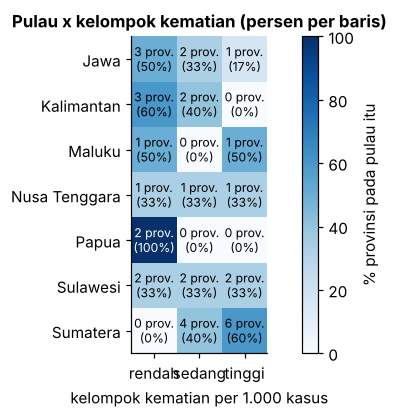

In [10]:
p['kelompok_kematian'] = pd.qcut(p['kematian_per_1000_kasus'], 3, labels=['rendah', 'sedang', 'tinggi'])
print('Batas tertil:', p.groupby('kelompok_kematian', observed=True)['kematian_per_1000_kasus'].agg(['min', 'max']).round(1).to_dict('index'))
ct = pd.crosstab(p['pulau'], p['kelompok_kematian'])
ct_pct = pd.crosstab(p['pulau'], p['kelompok_kematian'], normalize='index') * 100
print('\nJumlah provinsi:'); print(ct.to_string())
print('\nPersen per baris (baris = 100%):'); print(ct_pct.round(0).to_string())

chi2, pchi, dof, expected = stats.chi2_contingency(ct)
n = ct.values.sum(); r, k = ct.shape
V = np.sqrt(chi2 / (n * (min(r, k) - 1)))
phi2 = chi2 / n; phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1)); rc = r - (r - 1) ** 2 / (n - 1); kc = k - (k - 1) ** 2 / (n - 1)
V_koreksi = np.sqrt(phi2c / min(kc - 1, rc - 1))
print(f'\nchi2 = {chi2:.2f}, dof = {dof}, p = {pchi:.3f}, n = {n}')
print(f"Cramer's V = {V:.2f};  dikoreksi bias (Bergsma) = {V_koreksi:.2f}")
print(f'Sel dengan frekuensi harapan < 5: {(expected < 5).sum()} dari {expected.size} ({(expected < 5).mean() * 100:.0f}%);  terkecil = {expected.min():.2f}')

fig, ax = plt.subplots(figsize=(6.6, 3.9))
im = ax.imshow(ct_pct.values, cmap='Blues', vmin=0, vmax=100)
for i in range(r):
    for j in range(k):
        ax.text(j, i, f'{ct.values[i, j]} prov.\n({ct_pct.values[i, j]:.0f}%)', ha='center', va='center', fontsize=8, color='white' if ct_pct.values[i, j] > 60 else 'black')
ax.set_xticks(range(k)); ax.set_xticklabels(ct.columns); ax.set_yticks(range(r)); ax.set_yticklabels(ct.index); ax.grid(False)
fig.colorbar(im, ax=ax, label='% provinsi pada pulau itu')
ax.set_title('Pulau x kelompok kematian (persen per baris)'); ax.set_xlabel('kelompok kematian per 1.000 kasus')
plt.tight_layout(); plt.savefig(f'{FIGURES}/p7_crosstab.png', dpi=150); plt.show()

**Tafsiran.** Pola yang terbaca: seluruh provinsi Papua (2 dari 2) dan 60% Kalimantan ada di kelompok rendah; 60% provinsi Sumatera (6 dari 10) di kelompok tinggi dan tidak ada yang rendah. **Cramér's V mentah = 0,46** (tampak sedang), tetapi setelah koreksi bias turun menjadi **0,17** (lemah); selisih besar itu sendiri menandakan V mentah menggelembung, sehingga hasilnya **tidak dapat dipercaya sebagai bukti**: χ² tidak bermakna (p ≈ 0,29) dan **100% sel berfrekuensi harapan < 5** (terkecil 0,65), sehingga asumsi uji χ² dilanggar. Dilaporkan sebagai deskripsi pola, bukan uji, dengan kesimpulan yang sama seperti Kruskal-Wallis di bagian 4: arah perbedaan antarpulau ada (Sumatera cenderung disertai tingkat kematian lebih tinggi; Papua dan Kalimantan lebih rendah), kekuatannya tidak terbukti pada data sebesar ini.

## 6. Kandidat variabel perancu

**Untuk hubungan kepadatan–kasus (Pertanyaan 2).** *Intensitas pengujian dan pelaporan* kemungkinan mempengaruhi kedua sisi: provinsi padat dan perkotaan (Jakarta, Jawa) umumnya punya lebih banyak laboratorium dan fasilitas kesehatan sehingga lebih banyak kasus terdeteksi, sedangkan provinsi beraksesibilitas terbatas melaporkan lebih sedikit tanpa berarti penularannya lebih rendah. *Tingkat urbanisasi dan mobilitas*, serta *jumlah penduduk* sendiri (kepadatan dan penduduk berkorelasi 0,62), juga berkaitan dengan kedua sisi. Faceting (bagian 3) menunjukkan bahwa *pulau* membawa pola yang tidak seragam. Data kami tidak memuat jumlah tes, vaksinasi, atau umur, sehingga pengaruh-pengaruh ini **tidak dapat dikendalikan**, hanya disebut.

**Untuk hubungan kematian per 1.000 kasus dan pulau (Pertanyaan 4).** Kasus per juta berkorelasi **negatif** dengan kematian per 1.000 kasus (Spearman −0,51, p ≈ 0,002; Pearson −0,38; tanpa Jakarta Spearman −0,48). Pola ini sejalan dengan dugaan bahwa provinsi yang mendeteksi lebih sedikit kasus ringan memiliki penyebut lebih kecil sehingga rasionya naik: *cakupan pengujian* adalah kandidat perancu terkuat, yang tidak dapat diuji langsung. Kandidat lain: struktur umur, cakupan vaksinasi, dan ketersediaan rumah sakit. Karena itu perbedaan antarpulau di bagian 4–5 **tidak boleh dibaca sebagai perbedaan keparahan penyakit atau mutu layanan**; yang dapat dikatakan hanyalah perbedaan rasio kematian terhadap kasus *tercatat*.

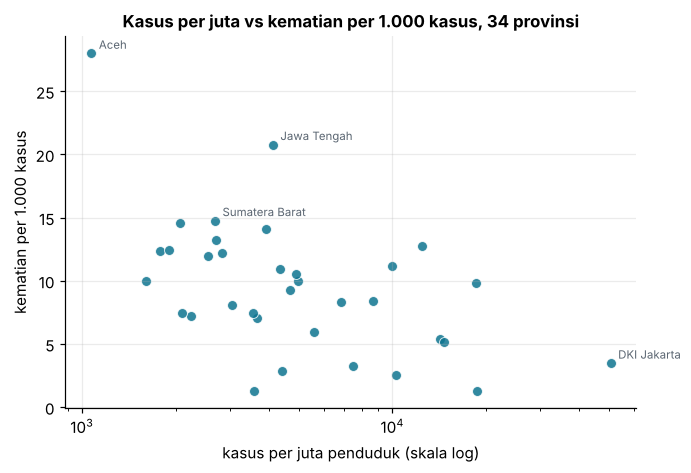

n = 34   Pearson r = -0.38 (p = 0.0276)   Spearman rho = -0.51 (p = 0.00218)
tanpa DKI Jakarta (n = 33):  Pearson r = -0.41   Spearman rho = -0.48 (p = 0.00484)


In [11]:
fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.scatter(p['kasus_per_juta'], p['kematian_per_1000_kasus'], s=42, color=DATA, alpha=.85, edgecolor='white', linewidth=.6)
for _, r in pd.concat([p.nlargest(3, 'kematian_per_1000_kasus'), p[p.provinsi == 'DKI Jakarta']]).iterrows():
    ax.annotate(r['provinsi'], (r['kasus_per_juta'], r['kematian_per_1000_kasus']), xytext=(5, 3), textcoords='offset points', fontsize=7.5, color=REDUP)
ax.set_xscale('log'); ax.set_xlabel('kasus per juta penduduk (skala log)'); ax.set_ylabel('kematian per 1.000 kasus')
ax.set_title('Kasus per juta vs kematian per 1.000 kasus, 34 provinsi')
plt.tight_layout(); plt.savefig(f'{FIGURES}/p7_scatter_kasuspj_kematian.png', dpi=150); plt.show()
lapor('kasus_per_juta', 'kematian_per_1000_kasus', tanpa='DKI Jakarta')

## 7. Ringkasan temuan dan jawaban sementara

| Pertanyaan | Jawaban sementara | Dasar | Keterbatasan |
|---|---|---|---|
| 1. Provinsi paling banyak / sedikit | Terbanyak: DKI Jakarta (547.214), Jawa Barat, Jawa Timur; tersedikit: Gorontalo (2.102), Maluku Utara, Sulawesi Barat. Per juta penduduk terendah: Aceh | `03_univariate` | Dipengaruhi pengujian; ≈57% kasus terjadi dalam satu bulan (Februari) |
| 2. Provinsi lebih padat = lebih banyak terkena? | Jumlah kasus: **ya, cenderung** (Spearman 0,62), tetapi penduduk lebih kuat (0,79). Kasus per kapita: **hampir tidak** tanpa Jakarta (Spearman 0,15–0,23, tak bermakna). Kelompok kepadatan M1: Padat 8.641 > Jarang 4.159 > Sedang 3.035, tidak monoton | 2a, 2b, 2c | n = 34; Jakarta berpengaruh; pola berubah antarpulau; tanpa data tes |
| 3. Pulau paling banyak | **Jawa** (1.631.428 kasus; 76,4%; 11.083 per juta) | `03_univariate`, M1 | `island` = pengelompokan dataset; satu-dua provinsi mendominasi tiap kelompok |
| 4. Kematian per 1.000 kasus; beda antarpulau? | Nasional 6,4. Gabungan: Sumatera 11,4 … Jawa 5,6 … Papua 2,0. **Berbeda secara deskriptif, tidak terbukti** (Kruskal p ≈ 0,10; V mentah 0,46 / terkoreksi 0,17; semua sel < 5) | bagian 4–5 | Rasio terhadap kasus terdeteksi; kasus per juta berkorelasi negatif dengannya |

## 8. Keluaran untuk perbandingan Python vs KNIME (M4, Pertemuan 11): korelasi

Bagian "korelasi" workflow KNIME dibandingkan dengan tabel di bagian 1. Hal yang perlu diperiksa agar selisih tidak disalahartikan sebagai salah hitung:

| Setelan | Python (notebook ini) | Yang diperiksa di KNIME |
|---|---|---|
| Jenis korelasi | Pearson **dan** Spearman (`scipy.stats`) | Apakah node yang dipakai menghitung Pearson saja; Spearman mungkin perlu node/langkah peringkat tersendiri |
| Data | Tingkat provinsi, **n = 34**, tanpa nilai kosong | Pastikan input KNIME sudah diagregasi per provinsi (bukan 8.770 baris harian), karena korelasi harian memberi angka yang sama sekali berbeda |
| Skala | Nilai asli (log hanya pada gambar) | Jangan transformasi log sebelum korelasi |
| Nilai kosong | Tidak ada pada 6 variabel ini (listwise = pairwise) | Perlakuan *missing* pada node korelasi |
| Ikatan peringkat (Spearman) | Rata-rata peringkat (bawaan SciPy) | Cara KNIME memperlakukan nilai kembar |
| Cramér's V | Mentah dan terkoreksi bias (Bergsma) | Rumus yang dipakai node; tabel 7×3 dengan n = 34 sangat peka |
| Uji signifikansi | p-value dua sisi (`scipy`) | Apakah KNIME melaporkan p-value |

Catatan: ini daftar hal yang *diperiksa*; setelan bawaan KNIME dicatat dari hasil workflow tim sendiri.

In [12]:
tbl.drop(columns='selisih').round(6).to_csv(f'{REPORTS}/p7_korelasi_pasangan.csv', index=False)
pear.round(6).to_csv(f'{REPORTS}/p7_korelasi_pearson.csv', index_label='variabel')
spea.round(6).to_csv(f'{REPORTS}/p7_korelasi_spearman.csv', index_label='variabel')
pd.DataFrame({'ukuran': ['chi2', 'dof', 'p_chi2', 'n', 'cramers_v_mentah', 'cramers_v_koreksi_bias', 'frek_harapan_terkecil', 'kruskal_H_pulau', 'kruskal_p_pulau'],
              'nilai': [chi2, dof, pchi, n, V, V_koreksi, expected.min(), H4, pH4]}).round(6).to_csv(f'{REPORTS}/p7_crosstab_cramer.csv', index=False)
pulau.round(4).to_csv(f'{REPORTS}/p7_kematian_per_pulau.csv', index_label='pulau')
print('Tersimpan di reports/:', sorted(f for f in os.listdir(REPORTS) if f.startswith('p7_')))
print('Tersimpan di reports/figures/:', sorted(f for f in os.listdir(FIGURES) if f.startswith('p7_')))

Tersimpan di reports/: ['p7_crosstab_cramer.csv', 'p7_kematian_per_pulau.csv', 'p7_korelasi_pasangan.csv', 'p7_korelasi_pearson.csv', 'p7_korelasi_spearman.csv']
Tersimpan di reports/figures/: ['p7_crosstab.png', 'p7_facet_pulau.png', 'p7_heatmap.png', 'p7_kematian_pulau.png', 'p7_scatter_kasuspj_kematian.png', 'p7_scatter_kepadatan_kasus.png', 'p7_scatter_kepadatan_kasuspj.png']


## Checklist sebelum mengumpulkan

- [x] Heatmap Pearson & Spearman berdampingan dengan skala warna yang sama.
- [x] Setiap angka korelasi disertai scatter plot-nya.
- [x] Pemilihan Pearson/Spearman beralasan sifat data, bukan besar angka.
- [x] n yang dilaporkan adalah n setelah `dropna()` (34).
- [x] Panel yang disandingkan memakai sumbu dan skala warna yang sama.
- [x] Tabel silang ternormalisasi per baris + Cramér's V, dengan peringatan sel kecil.
- [x] Faceting dengan keterangan apakah pola berubah.
- [x] Paragraf variabel perancu (lebih dari satu).
- [x] Tidak ada kalimat sebab-akibat.
- [x] Tabel provinsi diuji terhadap data olahan 02; kelompok kepadatan diuji terhadap M1.
- [x] Korelasi acuan untuk KNIME diekspor ke `reports/p7_*.csv`.
- [ ] Restart & Run All berjalan tanpa galat di komputer Anda.